# Dalili: A Destination Recommender Built from Scratch

This notebook is the complete machine-learning part of Dalili, from data to evaluated model. Run it top to bottom.

1. **Data**: Wikivoyage travel guides of 227 destinations, with hand labels for evaluation only.
2. **Vocabulary**: words become numbers, with subsampling and negative-sampling probabilities.
3. **Model**: Doc2Vec (PV-DBOW) plus skip-gram with negative sampling, **written from scratch in NumPy**. No ML library is used.
4. **Training**: mini-batch SGD with hand-written gradients, and the loss curve.
5. **Evaluation**: on a held-out test split, against a TF-IDF baseline (also from scratch) and random.
6. **Using the model**: similar places, "known for" words, a personal recommendation, and the taste map.

The data was exported by `python -m travel_agent.recommender.export_dataset` (see `dataset/README.md`). The same model code runs inside the website (`travel_agent/recommender/model.py`). The last section checks that this notebook reproduces the exact vectors the website uses.

In [1]:
import csv, json, time, zlib
from collections import Counter
from dataclasses import dataclass, field
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

DATA, MODELS = Path("dataset"), Path("models")
INTERESTS = ["beach", "culture", "history", "nature", "ski", "food", "nightlife", "shopping", "relax", "adventure"]
TAG_COLOR = {"beach": "#2bb3d6", "culture": "#9b8cff", "history": "#d99a3e", "nature": "#44c267", "ski": "#6fa8dc",
             "food": "#ff8a5c", "nightlife": "#d25bd8", "shopping": "#ff6b8b", "relax": "#3de0d0", "adventure": "#e0b030"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("NumPy", np.__version__)

NumPy 2.5.3


## 1. Data

Each destination has:
- its cleaned Wikivoyage guide, as **tokens** (the words the model reads);
- **hand labels** (1–4 interests) that the model never sees while training;
- its **split**: validation is used to choose settings, test is used only for the final numbers.

How the text was obtained:
1. Wikivoyage API, 50 pages per request.
2. Keep only the sections that describe a place.
3. Remove markup, stop-words and every place name; fold plurals; cap at 6,000 tokens.

The code for this is `travel_agent/recommender/corpus.py`.

In [2]:
rows = [json.loads(line) for line in open(DATA / "guides.jsonl", encoding="utf-8")]
data = [r for r in rows if r["split"] != "excluded"]          # St. Anton's guide is too short (< 150 tokens)
ids   = [r["id"] for r in data]
names = [r["name"] for r in data]
tags  = [r["tags"] for r in data]
docs  = [r["tokens"] for r in data]
split = np.array([r["split"] for r in data])
val, test = np.flatnonzero(split == "validation"), np.flatnonzero(split == "test")

print(f"{len(rows)} destinations, {len(data)} used ({len(val)} validation / {len(test)} test)")
print(f"{sum(map(len, docs)):,} tokens, {len({r['country'] for r in data})} countries")
b = names.index("Borovets")
print("\nExample -", names[b], tags[b], split[b])
print(data[b]["text"][:300], "...")
print("\ntokens:", " ".join(docs[b][:40]), "...")

228 destinations, 227 used (112 validation / 115 test)
430,333 tokens, 91 countries

Example - Borovets ['ski', 'nature'] validation
Borovets is a ski and mountain resort in Central Western Bulgaria, on the slopes of the Rila mountain range close to the town of Samokov. It's one of Bulgaria's most popular ski resorts and one of the starting points for hiking to Musala, the highest peak in Rila, Bulgaria and the Balkan Peninsula.
 ...

tokens: ski mountain resort slope rila mountain range close samokov ski resort starting point hiking musala highest peak rila balkan peninsula sure check sight samokov tsarska bistritsa palace palatial hunting lodge royalty built tsar ferdinand ruler modern later son boris nbsp ...


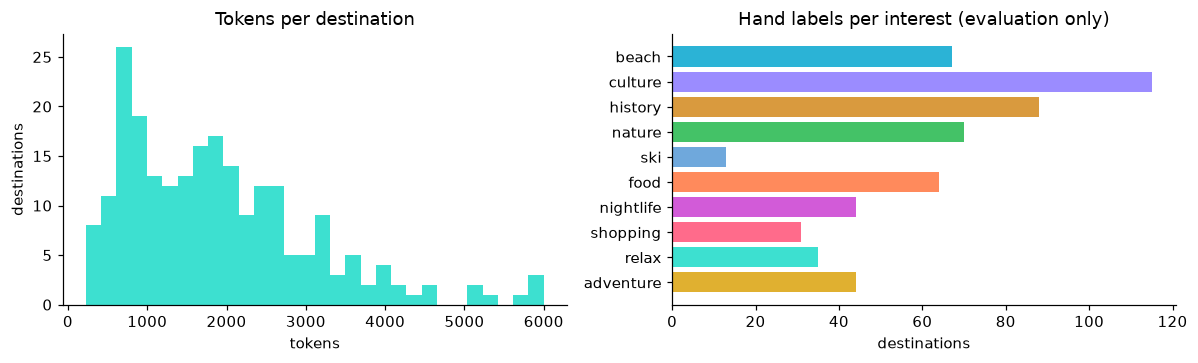

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist([len(d) for d in docs], bins=30, color="#3de0d0")
ax[0].set(title="Tokens per destination", xlabel="tokens", ylabel="destinations")
counts = [sum(t in tg for tg in tags) for t in INTERESTS]
ax[1].barh(INTERESTS, counts, color=[TAG_COLOR[t] for t in INTERESTS])
ax[1].set(title="Hand labels per interest (evaluation only)", xlabel="destinations")
ax[1].invert_yaxis()
plt.tight_layout(); plt.show()

## 2. The model, from scratch

**The idea.** Every destination *d* gets a vector **D_d**. Every word *w* gets an input vector **W_w** and an output vector **C_w**.

**Training pairs.** Training shows the model (input, target word) pairs:
- **PV-DBOW** (place → word): `borovets → ski`. A place vector must predict the words of its guide.
- **Skip-gram** (word → nearby word): `ski → slope`. A word must predict its neighbours.
- **Negative sampling**: for each true pair, random words drawn ∝ frequency^0.75 must *not* be predicted.

**Loss** for one pair (v = the input vector, σ = the sigmoid):

$$\mathcal{L} = -\log\sigma(v\cdot C_w) \;-\; \sum_{n \in \text{negatives}} \log\sigma(-v\cdot C_n)$$

**Gradients.** For a score *s = v·c*, the derivative is **σ(s) − 1** for the true word and **σ(s)** for a negative. These are written out by hand in `_step`.

**Why it works.** Places and words predict through the same **C**, so they end up in one space: *Santorini* lands near *Mykonos*, and the word *beach* lands near both.

**Speed-ups:**
- negatives are shared by the whole batch (weighted k/K, which gives the same expectation);
- gradient rows are added with a sort plus segment-sum.

In [4]:
def sigmoid(x):
    return 0.5 * (1.0 + np.tanh(0.5 * x))          # = 1 / (1 + e^-x), numerically stable

def unit(m):
    return m / np.maximum(np.linalg.norm(m, axis=-1, keepdims=True), 1e-9)

def scatter_add(M, idx, rows):
    # M[idx] += rows, summing repeated indices (sort + segment sum; faster than np.add.at)
    order = np.argsort(idx, kind="stable")
    s = idx[order]
    starts = np.flatnonzero(np.r_[True, s[1:] != s[:-1]])
    M[s[starts]] += np.add.reduceat(rows[order], starts, axis=0)


@dataclass
class Config:
    dim: int = 64               # vector size          (chosen on validation, see section 4)
    window: int = 3             # skip-gram context: 1..window words on each side
    negative: int = 6           # negatives per true pair (effective weight)
    shared_negatives: int = 64  # negatives drawn per batch, shared by all its pairs
    epochs: int = 30
    lr: float = 0.025           # learning rate, decays linearly to min_lr
    min_lr: float = 0.0001
    batch: int = 2048
    min_count: int = 3          # rarer words are left out of the vocabulary
    sample: float = 1e-3        # frequent-word subsampling threshold
    seed: int = 7


@dataclass
class Doc2Vec:
    cfg: Config = field(default_factory=Config)
    vocab: list = field(default_factory=list)
    history: list = field(default_factory=list)

    # ---- vocabulary ---------------------------------------------------------
    def build_vocab(self, docs):
        c = Counter(w for d in docs for w in d)
        self.vocab = sorted((w for w, n in c.items() if n >= self.cfg.min_count), key=lambda w: (-c[w], w))
        self.counts = np.array([c[w] for w in self.vocab], dtype=np.float64)
        self.w2i = {w: i for i, w in enumerate(self.vocab)}

    def encode(self, tokens):
        return np.array([self.w2i[t] for t in tokens if t in self.w2i], dtype=np.int64)

    def keep_prob(self):                      # frequent words are dropped more often
        f = self.counts / self.counts.sum()
        s = self.cfg.sample
        return np.minimum(1.0, (np.sqrt(f / s) + 1.0) * (s / f))

    def neg_cdf(self):                        # negatives drawn ∝ frequency^0.75
        p = self.counts ** 0.75
        return np.cumsum(p / p.sum())

    # ---- training pairs for one epoch -----------------------------------------
    def epoch_pairs(self, encoded, rng):
        keep, n_docs = self.keep_prob(), len(encoded)
        ins, outs = [], []
        for d, toks in enumerate(encoded):
            t = toks[rng.random(toks.size) < keep[toks]]
            if t.size < 2:
                continue
            ins.append(np.full(t.size, d)); outs.append(t)                 # PV-DBOW: place -> each word
            b = rng.integers(1, self.cfg.window + 1, t.size)               # random window per word
            for o in range(1, self.cfg.window + 1):                        # skip-gram: word -> neighbour
                fwd = b[:-o] >= o
                ins.append(n_docs + t[:-o][fwd]); outs.append(t[o:][fwd])
                bwd = b[o:] >= o
                ins.append(n_docs + t[o:][bwd]); outs.append(t[:-o][bwd])
        i, o = np.concatenate(ins), np.concatenate(outs)
        perm = rng.permutation(i.size)
        return i[perm], o[perm]

    # ---- one SGD step: forward, loss, hand-written gradients, update ------------
    @staticmethod
    def step(IN, OUT, ii, tt, nn, lr, neg_weight, update_out=True):
        h, o_pos, o_neg = IN[ii], OUT[tt], OUT[nn]              # (B,d) inputs, (B,d) true words, (K,d) negatives
        s_pos = sigmoid(np.einsum("bd,bd->b", h, o_pos))
        s_neg = sigmoid(h @ o_neg.T)                             # (B,K)
        loss = -np.log(s_pos + 1e-7).sum() - neg_weight * np.log(1.0 - s_neg + 1e-7).sum()
        g_pos = (s_pos - 1.0) * lr                               # dL/ds for the true word
        g_neg = s_neg * (lr * neg_weight)                        # dL/ds for each negative
        grad_h = g_pos[:, None] * o_pos + g_neg @ o_neg
        if update_out:
            scatter_add(OUT, tt, -g_pos[:, None] * h)
            scatter_add(OUT, nn, -(g_neg.T @ h))
        scatter_add(IN, ii, -grad_h)
        return float(loss)

    def fit(self, docs, verbose=True):
        cfg, rng = self.cfg, np.random.default_rng(self.cfg.seed)
        self.build_vocab(docs)
        encoded = [self.encode(d) for d in docs]
        V, n_docs = len(self.vocab), len(docs)
        IN = ((rng.random((n_docs + V, cfg.dim)) - 0.5) / cfg.dim).astype(np.float32)   # places, then words
        OUT = np.zeros((V, cfg.dim), dtype=np.float32)
        cdf = self.neg_cdf()
        total = self.epoch_pairs(encoded, np.random.default_rng(0))[0].size * cfg.epochs
        done, self.history = 0, []
        for ep in range(cfg.epochs):
            ii_all, tt_all = self.epoch_pairs(encoded, rng)
            loss_sum = 0.0
            for s in range(0, ii_all.size, cfg.batch):
                ii, tt = ii_all[s:s + cfg.batch], tt_all[s:s + cfg.batch]
                nn = np.minimum(np.searchsorted(cdf, rng.random(cfg.shared_negatives)), V - 1)
                lr = max(cfg.min_lr, cfg.lr * (1.0 - done / total))
                loss_sum += self.step(IN, OUT, ii, tt, nn, lr, cfg.negative / cfg.shared_negatives)
                done += ii.size
            self.history.append(loss_sum / ii_all.size)
            if verbose and (ep % 5 == 4 or ep == 0):
                print(f"epoch {ep + 1:2d}/{cfg.epochs}   pairs {ii_all.size:,}   loss {self.history[-1]:.4f}")
        self.D, self.W, self.C = IN[:n_docs], IN[n_docs:], OUT
        return self

### What goes into the model: vocabulary and training pairs

In [5]:
m = Doc2Vec()
m.build_vocab(docs)
encoded = [m.encode(d) for d in docs]
print(f"vocabulary: {len(m.vocab):,} words (seen >= {m.cfg.min_count} times)")
print("most frequent:", m.vocab[:12])
print("keep probability of 'restaurant' vs 'caldera':",
      round(float(m.keep_prob()[m.w2i['restaurant']]), 3), "vs", round(float(m.keep_prob()[m.w2i['caldera']]), 3))
print(f"\nBorovets as the model reads it ({encoded[b].size} word ids):", encoded[b][:15], "...")

ins, tgt = m.epoch_pairs(encoded, np.random.default_rng(1))
n_docs = len(docs)
print(f"\none epoch = {ins.size:,} (input -> target) pairs; examples:")
for i, t in list(zip(ins, tgt))[:8]:
    src = f"place:{ids[i]}" if i < n_docs else f"word:{m.vocab[i - n_docs]}"
    print(f"   {src:<28} -> {m.vocab[t]}")

vocabulary: 14,425 words (seen >= 3 times)
most frequent: ['restaurant', 'food', 'museum', 'park', 'street', 'world', 'shop', 'beach', 'island', 'old', 'price', 'building']
keep probability of 'restaurant' vs 'caldera': 0.522 vs 1.0

Borovets as the model reads it (223 word ids): [  426    50   198   909 13679    50    59   126   426   198   531   121
   253   514   460] ...

one epoch = 1,961,814 (input -> target) pairs; examples:


   place:medellin               -> completed
   word:simple                  -> experience
   place:medellin               -> licorice
   word:metropolitan            -> encompass
   word:carnival                -> attend
   word:offering                -> temple
   word:soviet                  -> socialist
   word:clothing                -> electronic


## 3. Training

epoch  1/30   pairs 1,962,209   loss 3.7867


epoch  5/30   pairs 1,962,634   loss 2.4579


epoch 10/30   pairs 1,962,561   loss 2.2383


epoch 15/30   pairs 1,960,318   loss 2.1415


epoch 20/30   pairs 1,960,975   loss 2.0779


epoch 25/30   pairs 1,962,396   loss 2.0324


epoch 30/30   pairs 1,962,607   loss 2.0004
trained in 292 s


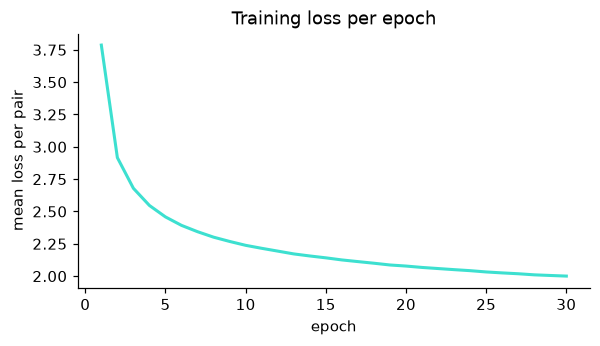

In [6]:
t0 = time.time()
model = Doc2Vec(Config()).fit(docs)
print(f"trained in {time.time() - t0:.0f} s")

plt.figure(figsize=(6, 3))
plt.plot(range(1, len(model.history) + 1), model.history, color="#3de0d0", lw=2)
plt.title("Training loss per epoch"); plt.xlabel("epoch"); plt.ylabel("mean loss per pair")
plt.show()

## 4. Evaluation on the held-out test split

**Metrics**
- **Similar places, Precision@5.** For each test destination, how many of its 5 nearest neighbours are "the same kind of place"? That means the same main label, or at least half of the labels shared.
- **Interests, MAP and Precision@10.** Rank the test destinations for each interest; the labelled ones should come first. An interest's vector is the mean of its seed words' vectors.

**Baselines**
- **TF-IDF** on the same tokens, written from scratch below.
- **Random ranking.**

**How the settings were chosen.** Five settings were compared on the **validation** split only; the one used above scored best. The test split was never used for choosing.

In [7]:
report = json.load(open(MODELS / "recommender_report.json", encoding="utf-8"))
print("settings compared on validation (from the training report):")
for r in report["tuning"]:
    c, v = r["config"], r["validation"]
    print(f"   dim {c['dim']:>3}  window {c['window']}  epochs {c['epochs']:>2}  negatives {c['negative']}  sample {c['sample']:<7}"
          f" ->  similar P@5 {v['sim_p@5']:.3f}   interest MAP {v[v['best_space'] + '_map']:.3f}")

settings compared on validation (from the training report):
   dim  96  window 4  epochs 15  negatives 6  sample 0.001   ->  similar P@5 0.541   interest MAP 0.677
   dim  96  window 4  epochs 30  negatives 6  sample 0.001   ->  similar P@5 0.546   interest MAP 0.663
   dim  64  window 3  epochs 30  negatives 6  sample 0.001   ->  similar P@5 0.571   interest MAP 0.688
   dim 128  window 4  epochs 30  negatives 8  sample 0.001   ->  similar P@5 0.529   interest MAP 0.655
   dim  96  window 4  epochs 30  negatives 6  sample 0.0001  ->  similar P@5 0.486   interest MAP 0.658


               similar P@5  interest MAP    P@10
Our Doc2Vec          0.558         0.631   0.640
TF-IDF               0.520         0.601   0.600
Random               0.278         0.248     nan


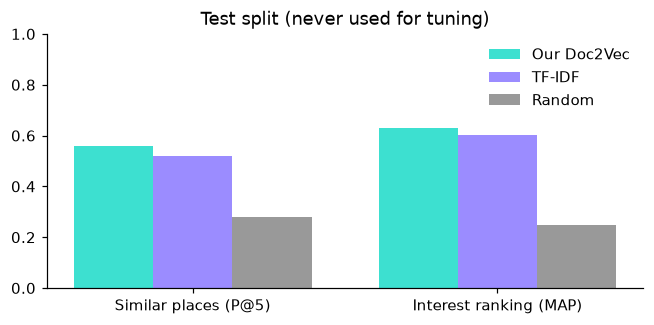

In [8]:
seeds = {r["interest"]: r["seed_words_in_vocabulary"].split() for r in csv.DictReader(open(DATA / "model_inputs" / "interest_seed_words.csv", encoding="utf-8"))}

def interest_matrix(vectors, w2i):
    return np.vstack([unit(unit(vectors[[w2i[w] for w in seeds[n] if w in w2i]]).mean(axis=0)) for n in INTERESTS])

def same_kind(i, j):
    a, b = set(tags[i]), set(tags[j])
    return tags[i][0] == tags[j][0] or len(a & b) / len(a | b) >= 0.5

def similar_p_at_5(X, queries):
    S = X @ X.T; np.fill_diagonal(S, -np.inf)
    return np.mean([np.mean([same_kind(i, j) for j in np.argsort(-S[i])[:5]]) for i in queries])

def average_precision(rel):
    hits = np.cumsum(rel)
    return float((hits / np.arange(1, rel.size + 1) * rel).sum() / max(rel.sum(), 1))

def interest_scores(X, Q, subset):
    ap, p10 = [], []
    for q, name in enumerate(INTERESTS):
        rel = np.array([name in tags[i] for i in subset], dtype=float)
        order = np.argsort(-(X[subset] @ Q[q]))
        ap.append(average_precision(rel[order])); p10.append(rel[order[:10]].mean())
    return np.mean(ap), np.mean(p10)

class TfIdf:                                   # the baseline, from scratch
    def fit(self, docs):
        df = Counter(w for d in docs for w in set(d))
        self.vocab = sorted(w for w, n in df.items() if n >= 2)
        self.w2i = {w: i for i, w in enumerate(self.vocab)}
        self.idf = np.array([np.log((1 + len(docs)) / (1 + df[w])) + 1 for w in self.vocab])
        self.X = np.vstack([self.transform(d) for d in docs]); return self
    def transform(self, tokens):
        v = np.zeros(len(self.vocab))
        for w, c in Counter(tokens).items():
            if w in self.w2i: v[self.w2i[w]] = 1 + np.log(c)
        v *= self.idf; n = np.linalg.norm(v); return v / n if n else v

X = unit(model.D)
Q = interest_matrix(model.C, model.w2i)          # interests as "which place predicts these words"
tf = TfIdf().fit(docs)
Qtf = np.vstack([tf.transform(seeds[n]) for n in INTERESTS])
rand_sim = np.mean([np.mean([same_kind(i, j) for j in range(len(docs)) if j != i]) for i in test])
rand_map = np.mean([np.mean([n in tags[i] for i in test]) for n in INTERESTS])

results = {
    "Our Doc2Vec": (similar_p_at_5(X, test), *interest_scores(X, Q, test)),
    "TF-IDF":      (similar_p_at_5(tf.X, test), *interest_scores(tf.X, Qtf, test)),
    "Random":      (rand_sim, rand_map, np.nan),
}
print(f"{'':<14}{'similar P@5':>12}{'interest MAP':>14}{'P@10':>8}")
for k, (s, a, p) in results.items():
    print(f"{k:<14}{s:>12.3f}{a:>14.3f}{p:>8.3f}")

fig, ax = plt.subplots(figsize=(7, 3))
w = 0.26
for i, (k, col) in enumerate(zip(results, ["#3de0d0", "#9b8cff", "#999999"])):
    ax.bar(np.arange(2) + (i - 1) * w, results[k][:2], w, label=k, color=col)
ax.set_xticks(range(2), ["Similar places (P@5)", "Interest ranking (MAP)"]); ax.set_ylim(0, 1)
ax.set_title("Test split (never used for tuning)"); ax.legend(frameon=False); plt.show()

## 5. What the model learned

In [9]:
def neighbours(name, k=5):
    i = names.index(name); s = X @ X[i]; s[i] = -np.inf
    return [names[j] for j in np.argsort(-s)[:k]]

for city in ["Borovets", "Santorini", "Kyoto", "Hurghada", "Marrakech", "Rome"]:
    print(f"{city:<10} -> {', '.join(neighbours(city))}")

# "Known for": words a place predicts much more strongly than an average place does (and found in several guides)
S = model.D @ model.C.T
lift = S - S.mean(axis=0, keepdims=True)
df = np.zeros(len(model.vocab)); [np.add.at(df, np.unique(e), 1) for e in [model.encode(d) for d in docs]]
lift[:, (df < 4) | (df > 0.35 * len(docs)) | (model.counts < 8)] = -np.inf
print()
for city in ["Santorini", "Borovets", "Dahab", "Kyoto", "Marrakech"]:
    print(f"{city:<10} known for: {', '.join(model.vocab[j] for j in np.argsort(-lift[names.index(city)])[:5])}")

print("\nTop places per interest:")
for q, n in enumerate(INTERESTS[:6]):
    print(f"   {n:<9} {', '.join(names[j] for j in np.argsort(-(X @ Q[q]))[:6])}")

Borovets   -> Bansko, Whistler, Zermatt, Aspen, Brașov
Santorini  -> Cyprus, Mykonos, Crete, Rhodes, Sicily
Kyoto      -> Tokyo, Taipei, Hokkaido, Beijing, Seoul
Hurghada   -> Sharm El Sheikh, Dubai, Dahab, Beirut, Alexandria
Marrakech  -> Fes, Chefchaouen, Luxor, Tunis, Baku
Rome       -> Florence, Milan, Venice, Naples, Prague



Santorini  known for: caldera, agio, volcanic, crater, windmill
Borovets   known for: hut, ski, snowboard, piste, balkan
Dahab      known for: padi, bedouin, diver, camel, freediving
Kyoto      known for: blossom, cherry, imperial, meditation, shrine
Marrakech  known for: dirham, medina, moroccan, atla, tagine

Top places per interest:
   beach     Hurghada, Mauritius, Bora Bora, Rhodes, Phuket, Maldives
   culture   Yerevan, Salzburg, Bucharest, Sofia, Reykjavík, Ljubljana
   history   Athens, Plovdiv, Aswan, Rhodes, Alexandria, Naples
   nature    Banff National Park, Yellowstone National Park, Plitvice Lakes National Park, Grand Canyon National Park, Whistler, Pokhara
   ski       Whistler, Borovets, Bansko, Chamonix, Zermatt, Aspen
   food      Nice, Thessaloniki, Siem Reap, Oaxaca, Porto, Hanoi


### A personal recommendation

A user's taste is the weighted sum of the vectors of what they did:

| Signal | Weight |
|---|---|
| Planned | 1.0 |
| Searched | 0.6 |
| Opened | 0.35 |
| Dismissed | −0.5 |
| An interest picked | 0.8 |

Places already seen are excluded. The website uses the same formula (`engine.py`), plus a 60-day fade for older signals.

In [10]:
history = [("planned", "Borovets", 1.0), ("searched", "Zermatt", 0.6), ("dismissed", "Aspen", -0.5)]
picked = ["nature"]
taste = sum(wt * X[names.index(c)] for _, c, wt in history)
score = 0.65 * (X @ unit(taste)) + 0.35 * np.mean([X @ Q[INTERESTS.index(i)] for i in picked], axis=0)
seen = {names.index(c) for _, c, _ in history}
top = [j for j in np.argsort(-score) if j not in seen][:6]
print("history:", history, "+ interests", picked)
for j in top:
    print(f"   {names[j]:<22} {' '.join(tags[j]):<25} match {100 * np.mean(score < score[j]):.0f}%")

history: [('planned', 'Borovets', 1.0), ('searched', 'Zermatt', 0.6), ('dismissed', 'Aspen', -0.5)] + interests ['nature']
   Bansko                 ski nature                match 99%
   Chamonix               ski nature adventure      match 98%
   Brașov                 history nature            match 98%
   Whistler               ski adventure             match 97%
   Pokhara                nature adventure relax    match 97%
   Banff National Park    nature ski adventure      match 96%


### The taste map: every destination in 2-D (PCA of the 64-d vectors)

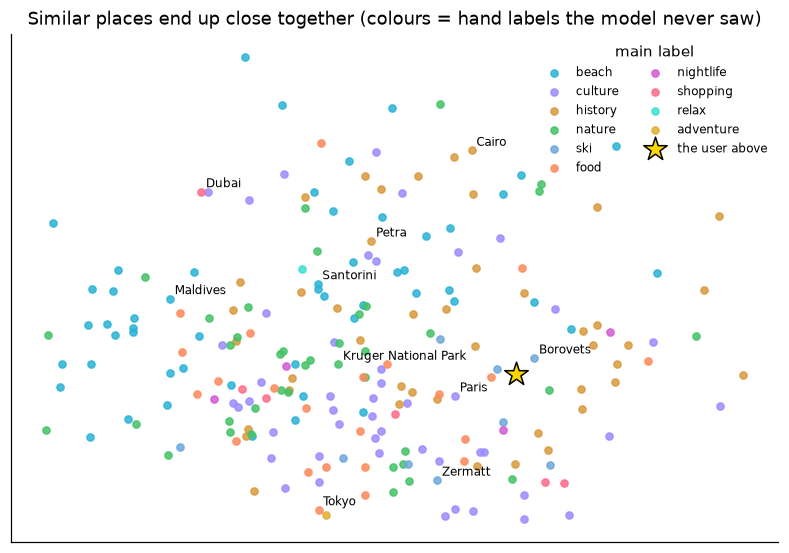

In [11]:
mu = X.mean(axis=0)
_, _, vt = np.linalg.svd(X - mu, full_matrices=False)
P = (X - mu) @ vt[:2].T
fig, ax = plt.subplots(figsize=(9, 6))
for t in INTERESTS:
    idx = [i for i in range(len(names)) if tags[i][0] == t]
    ax.scatter(P[idx, 0], P[idx, 1], s=22, color=TAG_COLOR[t], label=t, alpha=.85)
for c in ["Borovets", "Zermatt", "Santorini", "Maldives", "Cairo", "Paris", "Tokyo", "Dubai", "Petra", "Kruger National Park"]:
    i = names.index(c); ax.annotate(c, P[i], fontsize=8, xytext=(3, 3), textcoords="offset points")
me = (unit(taste) - mu) @ vt[:2].T
ax.scatter(*me, marker="*", s=260, color="gold", edgecolor="k", zorder=5, label="the user above")
ax.legend(ncol=2, fontsize=8, frameon=False, title="main label"); ax.set_xticks([]); ax.set_yticks([])
ax.set_title("Similar places end up close together (colours = hand labels the model never saw)")
plt.show()

## 6. Same model as the website

The website loads `models/recommender.npz`. It was trained by `python -m travel_agent.recommender.train --tune`, with the same code, data, settings and random seed. So this notebook should produce the same destination vectors.

In [12]:
saved = np.load(MODELS / "recommender.npz")
same_vocab = saved["vocab"].tolist() == model.vocab
diff = np.abs(saved["X"] - X).max()
print("same vocabulary:", same_vocab, "| largest difference between vectors:", f"{diff:.2e}")
print("saved model's test metrics:", report["test"]["similar_places_p@5"]["doc2vec"], "(P@5),",
      report["test"]["interests"]["doc2vec"]["map"], "(MAP)")

same vocabulary: True | largest difference between vectors: 0.00e+00
saved model's test metrics: 0.558 (P@5), 0.631 (MAP)


## Summary

- **Doc2Vec written from scratch.** It is trained on 227 destination guides (~430K tokens) and gives each place a 64-number vector.
- **It beats the baselines on the held-out test destinations.** It does better than TF-IDF and random both at finding similar places and at ranking places by interest.
- **The vectors power the website's "Picked for you".**
  - A user's taste vector is built from their trips, searches and interests.
  - Every suggestion states its reason and what the place is known for.
  - The taste map above is the same one shown on the dashboard.
- **Limitations.** The labels come from one annotator. Soft interests (food, nightlife) are harder than physical ones (beach, ski), because nearly every guide has *Eat* and *Drink* sections. The catalog is fixed at 228 places.